# IGNIS Earth · Notebook 2: baselines, models, applicability gate

**Input:** `celldays.parquet` from notebook 1 (one row per candidate cell per fire-day).
**Output:** `results.csv` (every number for the write-up), the frozen model files, `predictions.parquet` (for the demo), failure examples.

**The rules we follow, in order:**
1. **Train on 2014–2022, choose everything on 2023, touch 2024–25 once.** Never shuffle days.
2. **Baselines first.** The model only counts if it beats simple rules a firefighter could apply.
3. **Fix the gate and thresholds before looking at 2024–25.** Part A of this notebook never reads 2024–25. Part B (the test) is locked behind `RUN_TEST = False` until you decide to freeze.
4. **Report failures honestly.**

**Headline task = spread:** rows with `fire_today == 0` (cells not burning today): does the fire reach them tomorrow? Cells already burning (*continuing*) are reported separately.

**Credits.** Code drafted with help from Claude (Anthropic), reviewed and run by the team (list in Sources, Veritas rule 4).

In [50]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.inspection import permutation_importance

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
RNG = 0   # one random seed everywhere, so results repeat exactly

# Same data folder as notebook 1 (Google Drive)
DATA_DIR = Path("ignis_earth_data")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/ignis_earth_data")
except ImportError:
    print("Not on Colab: using local folder", DATA_DIR.resolve())
OUT_DIR = DATA_DIR / "model"; OUT_DIR.mkdir(exist_ok=True)

df = pd.read_parquet(DATA_DIR / "celldays.parquet")
# Split (changed Sat night): 2024 alone had only 39 spread cells, too few to tune on.
# Train 2014-2022, validate on 2023 (Evros, ~115 spread cells), test on 2024 + 2025 together (~80).
df["split"] = np.select([df.year <= 2022, df.year == 2023], ["train", "val"], "test")
df = df[(df.fire_today == 1) | (df.n_fire_1ring > 0)].reset_index(drop=True)   # spread = cells touching today's fire; 10 km jumps are new ignitions

# Recompute cell_clim from TRAINING years only (2014-2022). Notebook 1 used 2014-2023, which would
# leak 2023's own fires into the 2023 validation scores now that 2023 is the validation season.
fc = pd.read_parquet(DATA_DIR / "fire_cells.parquet")
fc = fc[fc.fire_day.dt.strftime("%m-%d").between("06-01", "09-30") & (fc.fire_day.dt.year <= 2022)].copy()
fc["month"] = fc.fire_day.dt.month
season_days = pd.Series(pd.date_range("2001-06-01", "2001-09-30").month).value_counts()   # days per month in season
clim = fc.groupby(["row", "col", "month"]).size().rename("n").reset_index()
clim["cell_clim"] = clim.n / (clim.month.map(season_days) * 9)                            # 9 training years
df["month"] = df.day.dt.month
df = df.drop(columns="cell_clim").merge(clim[["row", "col", "month", "cell_clim"]], on=["row", "col", "month"], how="left")
df["cell_clim"] = df.cell_clim.fillna(0.0)
TARGET = "fire_tomorrow"
print(f"{len(df):,} rows"); print(df.groupby("split").agg(rows=(TARGET, "size"), burn_tomorrow=(TARGET, "sum"),
                                                        newly_reached=("newly_reached", "sum")).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
43,082 rows
        rows  burn_tomorrow  newly_reached
split                                     
test    5212            184             60
train  34986           1745            986
val     2884            298             92


## Part A: everything decided on 2014–2023 (no 2024–25 anywhere)

### Features
* **M1 (logistic regression)** gets 8 physics-motivated features, so its coefficients can be explained one by one.
* **M2 (gradient boosting)** gets every feature from notebook 1.

In [51]:
M1_FEATURES = ["dist_to_fire", "wind_alignment", "upslope", "wind_max", "rh_min", "vpd_max",
               "days_since_rain", "cluster_size", "fire_today"]   # fire_today lets one model cover continuing cells too
M2_FEATURES = ["fire_today", "det_count_today", "frp_today", "fire_last_3d", "fire_last_7d",
               "n_fire_1ring", "n_fire_2ring", "frp_nearby", "dist_to_fire", "fire_age", "cluster_size",
               "wind_alignment", "upwind_nbr_fire", "upslope", "elev",
               "tmax", "rh_min", "wind_max", "gust_max", "wind_dir_sin", "wind_dir_cos", "vpd_max",
               "rain_today", "rain_7d", "days_since_rain", "et0_7d", "meltemi", "gust_x_downwind",
               "doy_sin", "doy_cos", "cell_clim"]
M2_FEATURES = [f for f in M2_FEATURES if f in df.columns]   # in case a Sunday add-on is missing

train = df[df.split == "train"].reset_index(drop=True)
val   = df[df.split == "val"].reset_index(drop=True)
print(f"train {len(train):,} rows ({train.year.min()}-{train.year.max()}), val {len(val):,} rows ({val.year.unique()})")
assert "test" not in set(train.split) | set(val.split)

train 34,986 rows (2014-2022), val 2,884 rows ([2023])


### Baselines
Each baseline gives a **score** per row (higher = more likely to burn tomorrow), so we can measure it exactly like a model.

| Name | Rule | Why |
|---|---|---|
| **B1 Persistence** | fire tomorrow if fire today | required by the Climate track; by design it predicts **zero** spread |
| **B2 Climatology** | the cell's training-years fire rate for that month | "just knowing fire-prone areas" |
| **B3 Neighbours** | every cell touching a burning cell burns tomorrow | a strong hand-written rule |
| **B5 Downwind rule** | cells touching a fire **on its downwind side** burn tomorrow (`upwind_nbr_fire`), ties broken by closeness and alignment | roughly what a firefighter would guess; **the main bar for spread** |

(B4, the Fire Weather Index, is an optional Sunday add-on.)

In [52]:
def baseline_scores(d):
    # Small tie-breaking terms only order cells WITHIN a rule's yes/no group, so the top-10 budget is fair.
    near = 1 - d.dist_to_fire / 15.0
    return {
        "B1_persistence": d.fire_today + 0.0,
        "B2_climatology": d.cell_clim + 0.0,
        "B3_neighbours":  ((d.fire_today == 1) | (d.n_fire_1ring > 0)).astype(float) + 0.01 * near,
        "B5_downwind":    ((d.fire_today == 1) | (d.upwind_nbr_fire == 1)).astype(float)
                          + 0.01 * (d.wind_alignment + 1) / 2 + 0.001 * near,
    }
# yes/no version of each rule (used for recall / precision / false alarms)
RULE_YES = {"B1_persistence": lambda d: d.fire_today == 1,
            "B3_neighbours":  lambda d: (d.fire_today == 1) | (d.n_fire_1ring > 0),
            "B5_downwind":    lambda d: (d.fire_today == 1) | (d.upwind_nbr_fire == 1)}

### Metrics
For each method, on a given set of rows:
* **Recall**: share of cells that really burned tomorrow that we warned about (1 − recall = missed spread).
* **Precision**: share of warnings that were real.
* **False alarms per day**: warned cells that did not burn, averaged over fire-days.
* **PR-AUC** (average precision): quality of the whole ranking, independent of any threshold. Better than accuracy here, because "never fire" would look very accurate.
* **Brier score**: is a 30% prediction right about 30% of the time? (models only; lower = better)
* **Top-10 per day**: if crews can cover only the 10 highest-scoring cells each day, how many burning cells do they catch?

In [53]:
def metrics(y, score, warn, days, name, subset, prob=None):
    y = np.asarray(y); warn = np.asarray(warn, dtype=bool)
    tp = (warn & (y == 1)).sum(); fp = (warn & (y == 0)).sum()
    n_days = pd.Series(days).nunique()
    # top-10 per day
    tmp = pd.DataFrame({"day": np.asarray(days), "s": np.asarray(score), "y": y})
    top = tmp.sort_values("s", ascending=False).groupby("day").head(10)
    return {"method": name, "subset": subset, "rows": len(y), "positives": int(y.sum()),
            "recall": tp / max(y.sum(), 1), "precision": tp / max(tp + fp, 1),
            "false_alarms_per_day": fp / max(n_days, 1),
            "pr_auc": average_precision_score(y, score) if 0 < y.sum() < len(y) else np.nan,
            "brier": brier_score_loss(y, prob) if prob is not None else np.nan,
            "top10_caught_per_day": top.y.sum() / max(n_days, 1),
            "top10_share_caught": top.y.sum() / max(y.sum(), 1)}

def evaluate(d, model_probs, thresholds, label):
    # d: rows to score. model_probs: {name: probability array}. Returns one table for spread and continuing rows.
    rows = []
    b = baseline_scores(d)
    for subset, mask in [("spread", d.fire_today.values == 0), ("continuing", d.fire_today.values == 1), ("all", np.ones(len(d), bool))]:
        dd = d[mask]
        for name, s in b.items():
            s = np.asarray(s)[mask]
            warn = RULE_YES[name](dd).values if name in RULE_YES else s >= np.quantile(np.asarray(b[name]), 0.9)
            rows.append(metrics(dd[TARGET], s, warn, dd.day, name, subset))
        for name, p in model_probs.items():
            p = np.asarray(p)[mask]
            rows.append(metrics(dd[TARGET], p, p >= thresholds[name], dd.day, name, subset, prob=p))
    out = pd.DataFrame(rows); out.insert(0, "season", label)
    return out

### M1: logistic regression (the explainable model)
Unweighted on purpose: `class_weight="balanced"` would push probabilities toward 50% and break calibration. We handle rarity with the threshold instead.

In [54]:
m1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
m1.fit(train[M1_FEATURES].fillna(train[M1_FEATURES].median()), train[TARGET])
M1_FILL = train[M1_FEATURES].median()          # missing values -> training median (saved with the model)
def m1_prob(d): return m1.predict_proba(d[M1_FEATURES].fillna(M1_FILL))[:, 1]

coef = pd.Series(m1[-1].coef_[0], index=M1_FEATURES).sort_values()
print("M1 coefficients (per 1 standard deviation; + pushes toward fire tomorrow):")
print(coef.round(3).to_string())

M1 coefficients (per 1 standard deviation; + pushes toward fire tomorrow):
dist_to_fire      -0.652
wind_max          -0.137
upslope           -0.093
fire_today        -0.042
rh_min            -0.030
wind_alignment     0.057
days_since_rain    0.067
vpd_max            0.181
cluster_size       0.323


### M2: gradient boosting (the main model), with a small search on 2023
We try a handful of settings, fit each on 2014–2022, and keep the one with the best **2023 spread PR-AUC**. HistGradientBoosting handles missing values on its own.

In [55]:
spread_val = val.fire_today.values == 0
search = []
for lr in [0.05, 0.1]:
    for n_trees in [100, 300]:
        for min_leaf in [20, 100]:      # bigger leaves = smoother model, less overfitting
            m = HistGradientBoostingClassifier(learning_rate=lr, max_iter=n_trees, min_samples_leaf=min_leaf,
                                               max_leaf_nodes=31, early_stopping=False, random_state=RNG)
            m.fit(train[M2_FEATURES], train[TARGET])
            p = m.predict_proba(val[M2_FEATURES])[:, 1]
            search.append({"learning_rate": lr, "max_iter": n_trees, "min_samples_leaf": min_leaf,
                           "val_spread_pr_auc": average_precision_score(val[TARGET][spread_val], p[spread_val])})
search = pd.DataFrame(search).sort_values("val_spread_pr_auc", ascending=False)
print(search.round(4).to_string(index=False))
best = search.iloc[0]
m2 = HistGradientBoostingClassifier(learning_rate=best.learning_rate, max_iter=int(best.max_iter),
                                    min_samples_leaf=int(best.min_samples_leaf), max_leaf_nodes=31,
                                    early_stopping=False, random_state=RNG)
m2.fit(train[M2_FEATURES], train[TARGET])
def m2_raw(d): return m2.predict_proba(d[M2_FEATURES])[:, 1]

 learning_rate  max_iter  min_samples_leaf  val_spread_pr_auc
          0.05       300                20             0.0905
          0.05       100                20             0.0888
          0.10       300                20             0.0864
          0.10       100                20             0.0800
          0.05       300               100             0.0748
          0.10       100               100             0.0745
          0.05       100               100             0.0686
          0.10       300               100             0.0641


### Calibration check on 2023
If the model says 30%, about 30% of those cells should burn. If the curve is far from the diagonal, we fit an **isotonic** correction on 2023 (only 2023, never 2024–25) and keep it if it lowers the Brier score.

2023 Brier: raw 0.1012, isotonic 0.0904 -> use isotonic: True


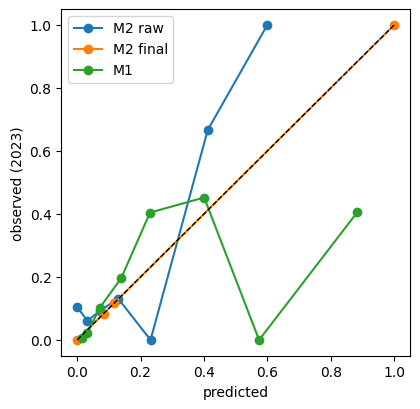

In [56]:
p_val_raw = m2_raw(val)
iso = IsotonicRegression(out_of_bounds="clip").fit(p_val_raw, val[TARGET])
brier_raw = brier_score_loss(val[TARGET], p_val_raw)
brier_iso = brier_score_loss(val[TARGET], iso.predict(p_val_raw))   # optimistic (fit on the same data), so require a clear gain
USE_ISO = brier_iso < 0.95 * brier_raw
print(f"2023 Brier: raw {brier_raw:.4f}, isotonic {brier_iso:.4f} -> use isotonic: {USE_ISO}")
def m2_prob(d):
    p = m2_raw(d)
    # isotonic makes flat steps (many cells with the same value); the tiny raw term keeps the original order,
    # so the ranking (PR-AUC, top-10) is unchanged and only the probabilities are corrected
    return np.clip(iso.predict(p) + 1e-6 * p, 0, 1) if USE_ISO else p

def reliability(y, p, ax, label):
    bins = pd.cut(p, [0, .02, .05, .1, .2, .3, .5, .7, 1.0], include_lowest=True)
    r = pd.DataFrame({"y": y, "p": p, "b": bins}).groupby("b", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    ax.plot(r.p, r.y, "o-", label=label)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
reliability(val[TARGET].values, p_val_raw, ax, "M2 raw")
reliability(val[TARGET].values, m2_prob(val), ax, "M2 final")
reliability(val[TARGET].values, m1_prob(val), ax, "M1")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted"); ax.set_ylabel("observed (2023)"); ax.legend(); plt.show()

### Warning thresholds (tuned on 2023 only)
* **(a) Recall-80 threshold:** the probability above which we catch 80% of 2023's newly reached cells.
* **(b) Alert budget:** the top 10 cells per day (computed directly in the metrics, no threshold needed).

In [57]:
def threshold_for_recall(y, p, target_recall=0.80):
    p_pos = np.sort(np.asarray(p)[np.asarray(y) == 1])[::-1]
    k = max(int(math.ceil(target_recall * len(p_pos))) - 1, 0)
    return float(p_pos[k]) if len(p_pos) else 0.5

VAL_PROBS = {"M1_logistic": m1_prob(val), "M2_boosting": m2_prob(val)}
# The MAIN model drives the gate table, direction metric, failure examples and the demo.
# Chosen on 2023 (validation): M1 had PR-AUC 0.116 vs 0.059 for M2, so the simpler model is the main one.
MAIN_MODEL = "M1_logistic"
THRESHOLDS = {name: threshold_for_recall(val[TARGET][spread_val], p[spread_val]) for name, p in VAL_PROBS.items()}
print("Thresholds (from 2023 spread rows):", {k: round(v, 4) for k, v in THRESHOLDS.items()})

Thresholds (from 2023 spread rows): {'M1_logistic': 0.0422, 'M2_boosting': 0.0839}


In [58]:
# DIAGNOSIS: why is spread hard? Uses training years + 2023 only (never the 2024-25 test).
fc_d = pd.read_parquet(DATA_DIR / "fire_cells.parquet")
fc_d["key"] = fc_d.fire_day.dt.strftime("%Y-%m-%d") + "_" + fc_d.row.astype(str) + "_" + fc_d.col.astype(str)
det_by_key = dict(zip(fc_d.key, fc_d.det_count))

dv = df[df.split.isin(["train", "val"])].copy()
sp_d = dv[dv.fire_today == 0].copy()
pos = sp_d[sp_d.fire_tomorrow == 1].copy()
tkey = (pos.day + pd.Timedelta(days=1)).dt.strftime("%Y-%m-%d") + "_" + pos.row.astype(str) + "_" + pos.col.astype(str)
pos["det_tomorrow"] = tkey.map(det_by_key)
n = len(pos)
def pct(x): return f"{100 * x.sum() / max(len(x), 1):.0f}%"

print(f"A. Spread cells (newly reached) in 2014-2023: {n:,}\n")
print("1. HOW FAR did the fire 'jump'? (distance from today's nearest burning cell)")
print("   touching today's fire (1 ring, about 5 km):", pct(pos.n_fire_1ring > 0))
print("   2 rings away (about 10 km, no burning neighbour):", pct(pos.n_fire_1ring == 0))
print("2. IS IT REALLY SPREAD, or noise?")
print("   only ONE satellite detection tomorrow:", pct(pos.det_tomorrow == 1))
print("   cell had fire in the 3 days before (re-detection, not new spread):", pct(pos.fire_last_3d > 0))
print("   nearest fire is a single cell (small fire):", pct(pos.cluster_size == 1))
plains = lambda d: (d.lat.between(39.2, 39.9) & d.lon.between(21.7, 22.9)) | (d.lat.between(40.5, 40.9) & d.lon.between(22.2, 22.9))
print("   in the farm plains (Thessaly / C. Macedonia):", pct(plains(pos)), " vs all candidate cells:", pct(plains(sp_d)))

print("\n3. DO FIRES EVEN CONTINUE? (per fire, per day)")
fires = dv.groupby("fire_id").agg(size=("cluster_size", "first"), any_tomorrow=("fire_tomorrow", "max"),
                                  spread=("newly_reached", "sum"))
print(f"   fires: {len(fires):,}   single-cell fires: {pct(fires['size'] == 1)}")
print("   fires with NO fire anywhere nearby tomorrow (died out / missed by satellite):", pct(fires.any_tomorrow == 0))
print("   ... single-cell fires that died:", pct(fires[fires['size'] == 1].any_tomorrow == 0),
      "  bigger fires that died:", pct(fires[fires['size'] > 1].any_tomorrow == 0))
print("   share of all spread cells that come from fires of 3+ cells:",
      f"{100 * fires[fires['size'] >= 3].spread.sum() / max(fires.spread.sum(), 1):.0f}%",
      " while those fires are", pct(fires['size'] >= 3), "of fires")

print("\n4. WHERE DOES THE MODEL (M1) DO WELL OR BADLY? 2023 spread cells")
v = val[val.fire_today == 0].assign(p=VAL_PROBS["M1_logistic"][spread_val])
groups = {"touching the fire (1 ring)": v.n_fire_1ring > 0, "2 rings away": v.n_fire_1ring == 0,
          "small fire (1 cell)": v.cluster_size == 1, "bigger fire (2+ cells)": v.cluster_size >= 2,
          "new fire (day 1)": v.fire_age <= 1, "older fire (2+ days)": v.fire_age >= 2,
          "calmer days (below median wind)": v.wind_max < v.wind_max.median(),
          "windier days (above median wind)": v.wind_max >= v.wind_max.median()}
rows = []
for name, m in groups.items():
    s = v[m]
    rows.append({"group": name, "rows": len(s), "spread cells": int(s.fire_tomorrow.sum()),
                 "base rate %": round(100 * s.fire_tomorrow.mean(), 2),
                 "PR-AUC": round(average_precision_score(s.fire_tomorrow, s.p), 3) if 0 < s.fire_tomorrow.sum() < len(s) else None})
g = pd.DataFrame(rows); g["PR-AUC / base"] = (g["PR-AUC"] / (g["base rate %"] / 100)).round(1)
print(g.to_string(index=False))


A. Spread cells (newly reached) in 2014-2023: 1,078

1. HOW FAR did the fire 'jump'? (distance from today's nearest burning cell)
   touching today's fire (1 ring, about 5 km): 100%
   2 rings away (about 10 km, no burning neighbour): 0%
2. IS IT REALLY SPREAD, or noise?
   only ONE satellite detection tomorrow: 47%
   cell had fire in the 3 days before (re-detection, not new spread): 22%
   nearest fire is a single cell (small fire): 45%
   in the farm plains (Thessaly / C. Macedonia): 60%  vs all candidate cells: 38%

3. DO FIRES EVEN CONTINUE? (per fire, per day)
   fires: 4,116   single-cell fires: 80%
   fires with NO fire anywhere nearby tomorrow (died out / missed by satellite): 78%
   ... single-cell fires that died: 85%   bigger fires that died: 50%
   share of all spread cells that come from fires of 3+ cells: 38%  while those fires are 8% of fires

4. WHERE DOES THE MODEL (M1) DO WELL OR BADLY? 2023 spread cells
                           group  rows  spread cells  base rate

### 2023 results (validation): baselines vs models
This is the table to iterate on tonight. It is **not** the final result; 2024–25 is.

In [59]:
COLS = ["method", "recall", "precision", "false_alarms_per_day", "pr_auc", "brier", "top10_caught_per_day", "top10_share_caught"]
res_val = evaluate(val, VAL_PROBS, THRESHOLDS, "2023 validation")
for subset in ["spread", "continuing"]:
    print(f"\n=== 2023, {subset} cells ===")
    print(res_val[res_val.subset == subset][COLS].round(3).to_string(index=False))


=== 2023, spread cells ===
        method  recall  precision  false_alarms_per_day  pr_auc  brier  top10_caught_per_day  top10_share_caught
B1_persistence   0.000      0.000                 0.000   0.040    NaN                 0.151               0.152
B2_climatology   0.087      0.036                 2.290   0.039    NaN                 0.183               0.185
 B3_neighbours   1.000      0.040                23.989   0.063    NaN                 0.312               0.315
   B5_downwind   0.598      0.065                 8.548   0.052    NaN                 0.280               0.283
   M1_logistic   0.804      0.097                 7.387   0.167  0.054                 0.473               0.478
   M2_boosting   0.804      0.049                15.548   0.091  0.040                 0.269               0.272

=== 2023, continuing cells ===
        method  recall  precision  false_alarms_per_day  pr_auc  brier  top10_caught_per_day  top10_share_caught
B1_persistence   1.000      0.367   

### What does the model rely on? (permutation importance, 2023 spread rows)
Shuffle one feature at a time and see how much the PR-AUC drops. Bigger drop = more important. Watch for surprises: from the Greece research, **`tmax` should not be the top feature** (Meltemi fires spread fast at moderate heat). If it is, check for a season effect or leakage.

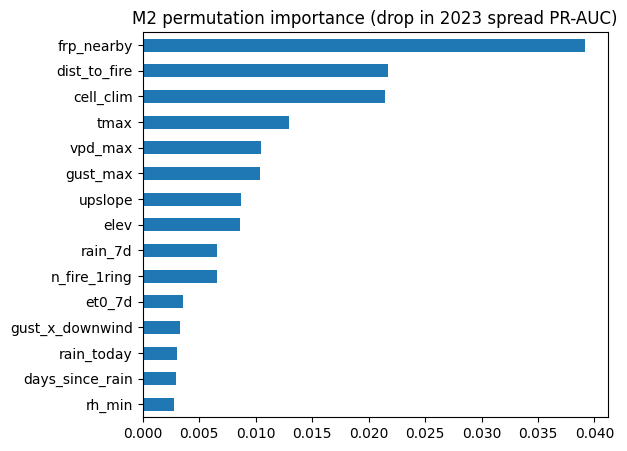

In [60]:
vs = val[spread_val].sample(min(20000, spread_val.sum()), random_state=RNG)
pi = permutation_importance(m2, vs[M2_FEATURES], vs[TARGET], scoring="average_precision", n_repeats=3, random_state=RNG)
imp = pd.Series(pi.importances_mean, index=M2_FEATURES).sort_values()
imp.tail(15).plot.barh(figsize=(6, 5), title="M2 permutation importance (drop in 2023 spread PR-AUC)"); plt.show()

### The applicability gate (the team's own idea)
**Question:** does the model get worse on days unlike anything it was trained on, and can it tell in advance?

**Version 1 (fixed now, before 2024–25):** from the training years, record the 1st and 99th percentile of six weather features. For each cell-day, count how many fall outside:
* 0 outside → **Supported** · 1 → **Limited** · 2 or more → **Unsupported**

**Version 2 (dissimilarity index, Area of Applicability idea):** distance from the cell-day's weather to the nearest training cell-day, divided by the typical distance between training cell-days. It also catches *unusual combinations* (e.g. moderate heat + extreme wind + very dry air) that v1 misses.

In [61]:
GATE_FEATURES = ["tmax", "rh_min", "wind_max", "gust_max", "vpd_max", "days_since_rain"]
ENVELOPE = {f: (float(train[f].quantile(0.01)), float(train[f].quantile(0.99))) for f in GATE_FEATURES}

def gate_v1(d):
    outside = pd.DataFrame({f: (d[f] < lo) | (d[f] > hi) for f, (lo, hi) in ENVELOPE.items()})
    n = outside.sum(axis=1)
    label = np.select([n == 0, n == 1], ["Supported", "Limited"], "Unsupported")
    reasons = outside.apply(lambda r: ", ".join(f for f in GATE_FEATURES if r[f]), axis=1)
    return n.values, label, reasons.values

# Version 2: dissimilarity index on scaled weather (one row per weather point per day, so it is fast)
from sklearn.neighbors import NearestNeighbors
_tw = train.drop_duplicates(["day", "wind_dir", "tmax", "rh_min"])[GATE_FEATURES].dropna()
_tw = _tw.sample(min(30000, len(_tw)), random_state=RNG)
GATE_SCALER = StandardScaler().fit(_tw)
_Z = GATE_SCALER.transform(_tw)
GATE_NN = NearestNeighbors(n_neighbors=2).fit(_Z)
_d_train = GATE_NN.kneighbors(_Z)[0][:, 1]              # nearest OTHER training row
_mean_dist = float(np.mean(np.linalg.norm(_Z[np.random.default_rng(RNG).integers(0, len(_Z), 5000)]
                                        - _Z[np.random.default_rng(RNG + 1).integers(0, len(_Z), 5000)], axis=1)))
DI_THRESHOLD = float(np.quantile(_d_train / _mean_dist, 0.99))
def gate_v2_di(d):
    Z = GATE_SCALER.transform(d[GATE_FEATURES].fillna(train[GATE_FEATURES].median()))
    return GATE_NN.kneighbors(Z, n_neighbors=1)[0][:, 0] / _mean_dist

print("Training envelope (1st-99th percentile):"); print(pd.DataFrame(ENVELOPE, index=["low", "high"]).T.round(1).to_string())
print(f"DI threshold (99th pct of training DI): {DI_THRESHOLD:.3f}")
n_out, lab, _ = gate_v1(val)
print("\n2023 gate labels:", pd.Series(lab).value_counts().to_dict())

Training envelope (1st-99th percentile):
                  low  high
tmax             17.2  39.1
rh_min           13.0  68.0
wind_max          5.4  36.9
gust_max         16.9  73.1
vpd_max           0.8   5.9
days_since_rain   0.0  68.0
DI threshold (99th pct of training DI): 0.382

2023 gate labels: {'Supported': 2653, 'Unsupported': 127, 'Limited': 104}


### Freeze: save everything that was decided without 2024–25
After this cell, **nothing in Part A may change** once the test has been run. Write the freeze time in the write-up.

In [62]:
joblib.dump({"m1": m1, "m1_fill": M1_FILL, "m2": m2, "iso": iso, "use_iso": USE_ISO,
             "m1_features": M1_FEATURES, "m2_features": M2_FEATURES, "thresholds": THRESHOLDS,
             "envelope": ENVELOPE, "gate_scaler": GATE_SCALER, "gate_nn": GATE_NN,
             "gate_mean_dist": _mean_dist, "di_threshold": DI_THRESHOLD}, OUT_DIR / "ignis_model.joblib")
json.dump({"main_model": MAIN_MODEL, "thresholds": THRESHOLDS, "envelope": ENVELOPE, "di_threshold": DI_THRESHOLD, "use_isotonic": bool(USE_ISO),
           "m2_settings": best.drop("val_spread_pr_auc").to_dict(), "frozen_at": pd.Timestamp.now(tz="Asia/Qatar").isoformat()},
          open(OUT_DIR / "frozen_settings.json", "w"), indent=1)
res_val.to_csv(OUT_DIR / "results_val_2023.csv", index=False)
print("Saved model and settings to", OUT_DIR)

Saved model and settings to /content/drive/MyDrive/ignis_earth_data/model


## Part B: the 2024–25 test (run ONCE, after the freeze)
Set `RUN_TEST = True` only when the team agrees Part A is final (plan: Sunday 2 PM). If you change Part A after seeing these numbers, the test is no longer honest; say so in the write-up if it happens.

In [63]:
RUN_TEST = True   # <- flip to True at the freeze, then Run all

In [64]:
assert RUN_TEST, "Test is locked. Set RUN_TEST = True at the freeze."
test = df[df.split == "test"].reset_index(drop=True)
TEST_PROBS = {"M1_logistic": m1_prob(test), "M2_boosting": m2_prob(test)}
res_test = evaluate(test, TEST_PROBS, THRESHOLDS, "2024–25 test")
for subset in ["spread", "continuing"]:
    print(f"\n=== 2024–25 TEST, {subset} cells ===")
    print(res_test[res_test.subset == subset][COLS].round(3).to_string(index=False))
pd.concat([res_val, res_test]).to_csv(OUT_DIR / "results.csv", index=False)
print("\nSaved results.csv (every number in the write-up must come from this file)")


=== 2024–25 TEST, spread cells ===
        method  recall  precision  false_alarms_per_day  pr_auc  brier  top10_caught_per_day  top10_share_caught
B1_persistence   0.000      0.000                 0.000   0.013    NaN                 0.074               0.233
B2_climatology   0.100      0.013                 2.405   0.013    NaN                 0.079               0.250
 B3_neighbours   1.000      0.013                23.237   0.022    NaN                 0.137               0.433
   B5_downwind   0.550      0.021                 7.979   0.021    NaN                 0.132               0.417
   M1_logistic   0.500      0.035                 4.384   0.040  0.014                 0.163               0.517
   M2_boosting   0.917      0.019                14.826   0.027  0.022                 0.111               0.350

=== 2024–25 TEST, continuing cells ===
        method  recall  precision  false_alarms_per_day  pr_auc  brier  top10_caught_per_day  top10_share_caught
B1_persistence   1.0

### Gate result on 2024–25: is the model worse on Limited / Unsupported days?
Plus the **risk–coverage curve**: sort test cell-days from most to least familiar, accept a growing share, and plot the error (Brier score) on the accepted ones. If the gate works, the curve **rises to the right**: the model is more accurate on the days it says it can handle.

       gate  spread_rows  share_%  newly_reached  recall  false_alarm_rate  pr_auc  brier
  Supported         4099   91.598             51   0.431             0.187   0.031  0.013
    Limited          235    5.251              5   1.000             0.187   0.320  0.019
Unsupported          141    3.151              4   0.750             0.248   0.076  0.027


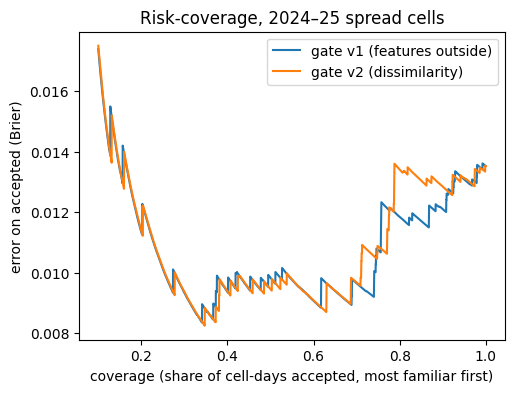

In [65]:
p = TEST_PROBS[MAIN_MODEL]
n_out, lab, reasons = gate_v1(test)
di = gate_v2_di(test)
test_g = test.assign(prob=p, gate=lab, gate_reasons=reasons, n_outside=n_out, di=di, di_unsupported=di > DI_THRESHOLD)

rows = []
for g in ["Supported", "Limited", "Unsupported"]:
    s = test_g[(test_g.gate == g) & (test_g.fire_today == 0)]
    if len(s) == 0: rows.append({"gate": g, "spread_rows": 0}); continue
    warn = s.prob >= THRESHOLDS[MAIN_MODEL]
    rows.append({"gate": g, "spread_rows": len(s), "share_%": 100 * len(s) / (test_g.fire_today == 0).sum(),
                 "newly_reached": int(s[TARGET].sum()),
                 "recall": (warn & (s[TARGET] == 1)).sum() / max(s[TARGET].sum(), 1),
                 "false_alarm_rate": (warn & (s[TARGET] == 0)).sum() / max((s[TARGET] == 0).sum(), 1),
                 "pr_auc": average_precision_score(s[TARGET], s.prob) if 0 < s[TARGET].sum() < len(s) else np.nan,
                 "brier": brier_score_loss(s[TARGET], s.prob)})
gate_table = pd.DataFrame(rows); print(gate_table.round(3).to_string(index=False))
gate_table.to_csv(OUT_DIR / "results_gate_test.csv", index=False)

# risk-coverage curves for both gate versions
sp = test_g[test_g.fire_today == 0]
err = (sp.prob - sp[TARGET]) ** 2
fig, ax = plt.subplots(figsize=(5.5, 4))
for name, fam in [("gate v1 (features outside)", sp.n_outside + 1e-6 * sp.di), ("gate v2 (dissimilarity)", sp.di)]:
    order = np.argsort(fam.values)
    cov = np.arange(1, len(order) + 1) / len(order)
    risk = np.cumsum(err.values[order]) / np.arange(1, len(order) + 1)
    keep = cov >= 0.1
    ax.plot(cov[keep], risk[keep], label=name)
ax.set_xlabel("coverage (share of cell-days accepted, most familiar first)"); ax.set_ylabel("error on accepted (Brier)")
ax.set_title("Risk-coverage, 2024–25 spread cells"); ax.legend(); plt.show()

### Spread direction: does the model point the right way?
For each fire that grew into new cells tomorrow: the **predicted** direction is from the fire's burning cells to the probability-weighted centre of its candidate cells; the **real** direction is toward the centre of the cells it actually reached. We compare that angle with simply using the wind direction.

In [66]:
def bearing(dlat, dlon, lat):
    return np.degrees(np.arctan2(dlon * np.cos(np.radians(lat)), dlat)) % 360
def angle_diff(a, b): return np.abs((a - b + 180) % 360 - 180)

out = []
for fid, f in test_g.groupby("fire_id"):
    burn, new = f[f.fire_today == 1], f[(f.fire_today == 0) & (f[TARGET] == 1)]
    cand = f[f.fire_today == 0]
    if len(burn) == 0 or len(new) == 0 or cand.prob.sum() == 0: continue
    c_lat, c_lon = burn.lat.mean(), burn.lon.mean()
    w = (cand.prob - cand.prob.mean()).clip(lower=0)      # only cells above the fire's average count
    if w.sum() == 0: continue
    pred = bearing(np.average(cand.lat, weights=w) - c_lat, np.average(cand.lon, weights=w) - c_lon, c_lat)
    real = bearing(new.lat.mean() - c_lat, new.lon.mean() - c_lon, c_lat)
    wind = (f.wind_dir.iloc[0] + 180) % 360            # direction the wind blows toward
    out.append({"fire_id": fid, "n_new": len(new), "err_model": angle_diff(pred, real), "err_wind": angle_diff(wind, real)})
direction = pd.DataFrame(out)
if len(direction):
    print(f"{len(direction)} fires that spread. Median angle error: model {direction.err_model.median():.0f} deg, "
          f"wind alone {direction.err_wind.median():.0f} deg")
    direction.to_csv(OUT_DIR / "results_direction_test.csv", index=False)

36 fires that spread. Median angle error: model 68 deg, wind alone 80 deg


### Failure examples (pick two for the write-up and video)
* **Missed spread:** cells that burned tomorrow but got a low probability (often a jump of more than one cell: embers, or a missed detection).
* **False alarm:** high probability, nothing burned.

Before blaming the model, check each one against **satellite blind spots** (cloud, smoke, dense canopy, short fires between passes): look at the cloud that day and at Sentinel-2 / Landsat a few days later for a burn scar. Say whether it is a *model* error or a *label* error.

Worst misses:
       day    fire_id    lat    lon  prob  dist_to_fire  wind_alignment  gust_max  rh_min      gate gate_reasons
2024-09-29 20240929_2 38.075 22.475 0.012         7.049           0.907      56.9      32 Supported             
2024-09-21 20240921_1 38.075 23.625 0.012         7.049          -0.750      46.1      34 Supported             
2025-06-22 20250622_1 38.125 23.575 0.013         7.049          -0.722      49.7      23 Supported             
2024-08-11 20240811_3 38.175 23.975 0.017         7.049           0.566      63.4      28 Supported             
2024-08-11 20240811_3 38.175 23.875 0.018         7.049           0.935      63.4      28 Supported             
2025-06-22 20250622_2 38.325 26.075 0.018         7.049           0.963      69.5      30 Supported             
2024-09-29 20240929_2 38.075 22.425 0.018         5.566           0.452      56.9      32 Supported             
2025-07-21 20250721_1 38.125 23.575 0.023         7.049           0.882      41.0 

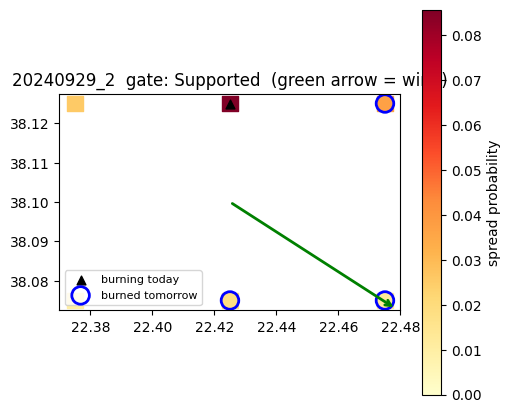

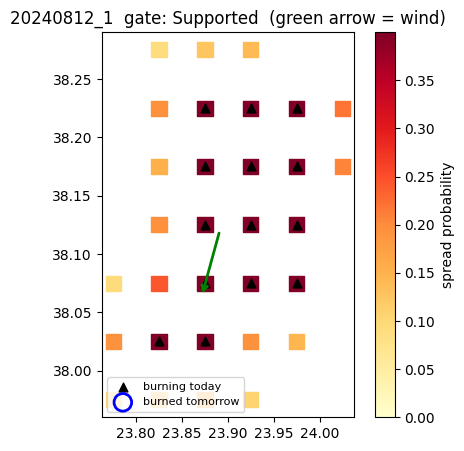

In [67]:
sp = test_g[test_g.fire_today == 0]
missed = sp[sp[TARGET] == 1].sort_values("prob").head(10)
false_alarms = sp[sp[TARGET] == 0].sort_values("prob", ascending=False).head(10)
show = ["day", "fire_id", "lat", "lon", "prob", "dist_to_fire", "wind_alignment", "gust_max", "rh_min", "gate", "gate_reasons"]
R3 = {c: 3 for c in ["prob", "dist_to_fire", "wind_alignment"]}
print("Worst misses:"); print(missed[show].round(R3).to_string(index=False))
print("\nWorst false alarms:"); print(false_alarms[show].round(R3).to_string(index=False))

def plot_fire(fid):
    f = test_g[test_g.fire_id == fid]
    fig, ax = plt.subplots(figsize=(5.5, 5))
    sc = ax.scatter(f.lon, f.lat, c=f.prob, cmap="YlOrRd", s=120, marker="s", vmin=0, vmax=max(f.prob.max(), 0.05))
    b = f[f.fire_today == 1]; ax.scatter(b.lon, b.lat, marker="^", c="black", s=40, label="burning today")
    n = f[(f.fire_today == 0) & (f[TARGET] == 1)]; ax.scatter(n.lon, n.lat, facecolors="none", edgecolors="blue", s=160, lw=2, label="burned tomorrow")
    w = math.radians((f.wind_dir.iloc[0] + 180) % 360)
    ax.annotate("", xy=(f.lon.mean() + 0.06 * math.sin(w), f.lat.mean() + 0.06 * math.cos(w)), xytext=(f.lon.mean(), f.lat.mean()),
                arrowprops=dict(arrowstyle="->", lw=2, color="green"))
    ax.set_title(f"{fid}  gate: {f.gate.iloc[0]}  (green arrow = wind)"); plt.colorbar(sc, label="spread probability")
    ax.legend(loc="lower left", fontsize=8); ax.set_aspect(1 / math.cos(math.radians(f.lat.mean()))); plt.show()

plot_fire(missed.fire_id.iloc[0])
plot_fire(false_alarms.fire_id.iloc[0])

In [68]:
# Save predictions for the demo (2023 and 2024–25 only)
preds = pd.concat([val.assign(prob=VAL_PROBS[MAIN_MODEL], prob_m2=VAL_PROBS["M2_boosting"]),
                   test.assign(prob=TEST_PROBS[MAIN_MODEL], prob_m2=TEST_PROBS["M2_boosting"])], ignore_index=True)
n_out, lab, reasons = gate_v1(preds)
preds = preds.assign(gate=lab, gate_reasons=reasons, di=gate_v2_di(preds))
preds["di_unsupported"] = preds.di > DI_THRESHOLD
preds.to_parquet(OUT_DIR / "predictions.parquet", index=False)
print("Saved predictions.parquet for 03_demo:", len(preds), "rows")

Saved predictions.parquet for 03_demo: 8096 rows


## Hand-over
In `ignis_earth_data/model/`: `results.csv` (all numbers), `results_gate_test.csv`, `results_direction_test.csv`, `ignis_model.joblib`, `frozen_settings.json`, `predictions.parquet` (for the demo).

**For the write-up:** quote the **spread** rows of the 2024–25 table (model vs **B5 downwind rule**), the gate table, the risk–coverage chart and the direction result. If the model does not beat B5, say so plainly and show where it does help (strong wind, uphill, big fires): judges score an honest modest result above an unexplained high one.